# Фиксированные ансамбли и попарные классификаторы зданий

Новых обучений нейросети здесь нет. Четыре равновесных сочетания probabilities заранее фиксированы, без сетки весов. Затем три бинарные logistic regression используют замороженные 2048 признаков ResNet101: church/palace, church/commercial_area, palace/commercial_area.

**Fitting только на train.** Стандартизация отдельно по train соответствующей пары, C=1, L2, LBFGS. sklearn/scipy не требуются. Val используется только для сравнения. Маршрутизация — исходные top-2, независимо от confidence и истинного класса. Правильно распознанные здания тоже могут попасть к классификатору: считаем fixes **и** breaks на всей val.

Существующие веса, experiments.csv и исходные predictions остаются неизменными. Результаты и обученные линейные классификаторы сохраняются в отдельных inference-run директориях. Кэш признаков содержит только train трёх классов и все val; test не читается.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
from src.frozen_experiments import run_fixed_ensembles, run_pairwise
from src.pairwise import extract_building_features

DEVICE = 'auto'
CPU_THREADS = 4
BATCH_SIZE = 8
ENSEMBLE_RUN_ID = 'frozen_probability_ensembles_001'
PAIRWISE_RUN_ID = 'frozen_building_reranker_001'
FEATURE_DIR = 'artifacts/predictions/building_pairwise_features_001'
CHECKPOINT = 'artifacts/models/resnet101_partial_domain_shift_stronger_001/best.pt'


## 1. Четыре фиксированных probability ensembles

Reference: mean(ResNet101 none, stronger50 D4), 679/699. Добавление CosFace/mining означает равные веса трёх исходных моделей, а не 50% новому участнику. D4 считается одним участником. fixes/breaks в таблице относительно reference.

In [2]:
ensemble_results = run_fixed_ensembles(PROJECT_ROOT, ENSEMBLE_RUN_ID)
display(ensemble_results)


,recipe,correct,errors,val_accuracy,fixes,breaks,val_nll,reference
0,stronger_single,675,24,0.965665,5,9,0.184112,reference_101_50d4
1,resnet101_single,678,21,0.969957,4,5,0.163261,reference_101_50d4
2,reference_101_50d4,679,20,0.971388,0,0,0.132275,reference_101_50d4
3,stronger_cosface_mining,676,23,0.967096,3,6,0.149609,reference_101_50d4
4,stronger_smoothing_cosface_mining,675,24,0.965665,3,7,0.137947,reference_101_50d4
5,resnet101_stronger_d4_cosface,677,22,0.968526,1,3,0.128870,reference_101_50d4
6,resnet101_stronger_d4_mining,679,20,0.971388,3,3,0.133824,reference_101_50d4


## 2. Замороженные признаки

Первый запуск делает CPU/GPU inference на ~750 train зданий и 699 val. Завершённый кэш повторно используется с проверкой hashes. Никаких аугментаций, TTA или градиентов backbone.

In [3]:
feature_path = extract_building_features(PROJECT_ROOT, CHECKPOINT, FEATURE_DIR,
    device=DEVICE, batch_size=BATCH_SIZE, cpu_threads=CPU_THREADS)
display(json.loads((feature_path/'metadata.json').read_text(encoding='utf-8')))


{'protocol': {'version': 1,
  'checkpoint_sha256': '753850b365640e0ca2c6d4df49b722d5e9ce846d3eef11367962ab306107775b',
  'train_csv_sha256': '3691c8f04d5b8a8f8310793f50142b8153231bc2b1ba83c81e8bd56ad64cd45b',
  'val_csv_sha256': 'a3c3523da9d76384da5ada6c7d0bf053cfbd22fe28e483cb8922be1f6c28ea6c',
  'classes_csv_sha256': 'ff149922fb9b47cea6120deb532c6ff69e8afe1046f000637c75ea085bb8f1c1',
  'train_classes': [3, 5, 9],
  'views': 'clean_full_frame',
  'feature_location': 'backbone.fc input before dropout'},
 'status': 'complete',
 'test_read': False,
 'neural_training': False,
 'device': 'cpu',
 'torch': '2.14.1+cpu',
 'hashes': {'train.npz': '67281be8c21963f74885bfa84e2bcd210616922767d0234640f904e6f62c983d',
  'val.npz': '1e55a2dfbd029e7f42ef22a7d1dc2299ec3a4bb6ab2a739d715aaed57e70ffa0'},
 'elapsed_seconds': 453.66528510000353}

## 3. Train-only logistic regression и top-2 reranking

Одни и те же три классификатора применяем к одиночной 101 и прежнему лучшему ансамблю. Пороги/веса по val не подбираются. Результат сохраняется как labels, без выдуманного 20-классового распределения вероятностей.

In [4]:
pairwise_results = run_pairwise(PROJECT_ROOT, FEATURE_DIR, PAIRWISE_RUN_ID)
display(pairwise_results)
pair_logs = PROJECT_ROOT/'artifacts/logs'/PAIRWISE_RUN_ID
display(pd.read_csv(pair_logs/'binary_diagnostics.csv'))
display(pd.read_csv(pair_logs/'routing_summary.csv'))


,recipe,correct,errors,val_accuracy,fixes,breaks,reference,routed,changed,elapsed_fit_seconds
0,resnet101_single_pairwise,677,22,0.968526,1,2,resnet101_single,83,3,10.036679
1,reference_101_50d4_pairwise,677,22,0.968526,1,3,reference_101_50d4,87,4,10.086622


,pair,train_samples,train_accuracy,val_pair_samples,val_pair_correct,val_pair_accuracy,iterations,gradient_max,converged
0,3_9,499,1.0,70,66,0.942857,37,8.000478e-07,True
1,3_5,500,1.0,70,67,0.957143,35,6.798069e-07,True
2,9_5,499,1.0,70,66,0.942857,34,8.597099e-07,True


,base,pair,routed,changed,correct_before,correct_after,fixes,breaks,outside_true_pair
0,resnet101_single,3_5,24,2,21,21,1,1,0
1,resnet101_single,3_9,39,0,36,36,0,0,0
2,resnet101_single,9_5,20,1,18,17,0,1,0
3,reference_101_50d4,3_5,22,2,20,20,1,1,0
4,reference_101_50d4,3_9,42,0,38,38,0,0,0
5,reference_101_50d4,9_5,23,2,21,19,0,2,0


## 4. Сравнение результатов и всех изменений

resnet101_single
reference_101_50d4


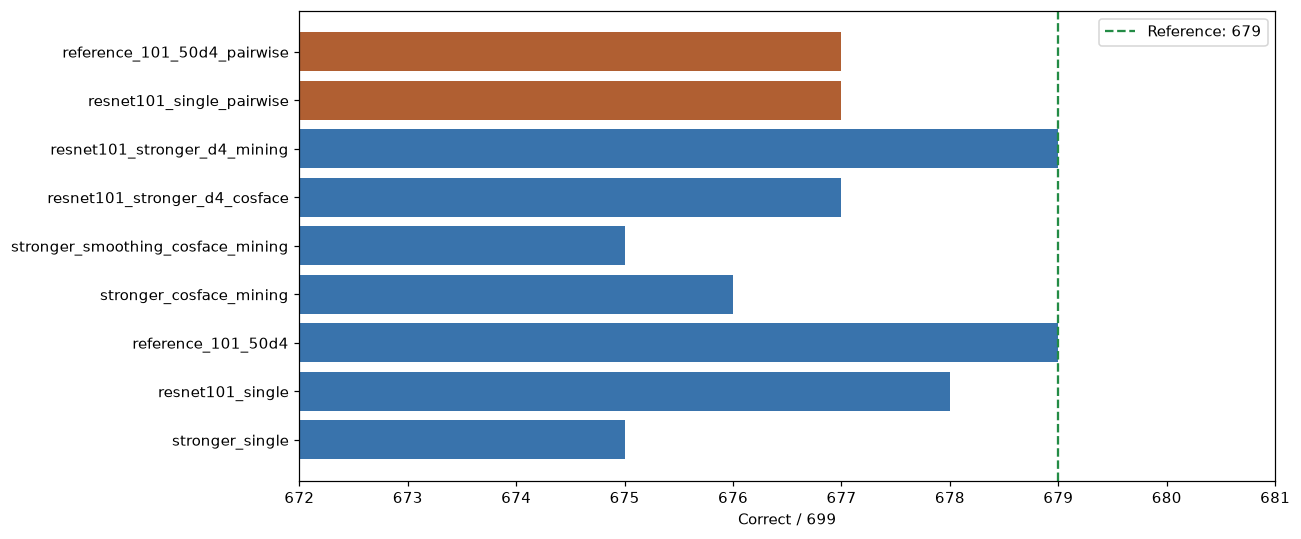

,id,true_label,reference_label,label,true_class,reference_class,predicted_class,change
0,2200.jpg,9,9,5,palace,palace,commercial_area,break
1,9099.jpg,5,5,3,commercial_area,commercial_area,church,break
2,12684.jpg,3,5,3,church,commercial_area,church,fix


,label,class_name,support,errors
1,1,basketball_court,35,2
3,3,church,35,6
5,5,commercial_area,35,1
6,6,lake,35,4
9,9,palace,35,3
10,10,railway,35,1
11,11,railway_station,35,1
15,15,sea_ice,35,1
18,18,terrace,35,1
19,19,wetland,35,2


,id,true_label,reference_label,label,true_class,reference_class,predicted_class,change
0,2200.jpg,9,9,5,palace,palace,commercial_area,break
1,7548.jpg,3,3,5,church,church,commercial_area,break
2,9099.jpg,5,5,9,commercial_area,commercial_area,palace,break
3,12684.jpg,3,5,3,church,commercial_area,church,fix


,label,class_name,support,errors
0,0,baseball_diamond,35,1
1,1,basketball_court,35,3
3,3,church,35,6
5,5,commercial_area,35,1
6,6,lake,35,3
9,9,palace,35,3
11,11,railway_station,35,1
17,17,tennis_court,35,1
18,18,terrace,35,2
19,19,wetland,35,1


In [5]:
comparison = pd.concat([ensemble_results[['recipe','correct','errors','val_accuracy']],
                        pairwise_results[['recipe','correct','errors','val_accuracy']]], ignore_index=True)
fig, ax = plt.subplots(figsize=(12,5))
ax.barh(comparison.recipe, comparison.correct, color=['#3973ac']*len(ensemble_results)+['#b05f32']*len(pairwise_results))
ax.axvline(679,color='#238b45',linestyle='--',label='Reference: 679')
ax.set(xlim=(min(comparison.correct)-3, max(comparison.correct)+2), xlabel='Correct / 699')
ax.legend(); fig.tight_layout(); plt.show()
for base in ['resnet101_single','reference_101_50d4']:
    print(base)
    display(pd.read_csv(pair_logs/f'{base}_changes.csv'))
    display(pd.read_csv(pair_logs/f'{base}_classes.csv').query('errors > 0'))


## 5. Изображения, на которых reranker поменял ответ

Показываем все изменения, включая регрессии, без выбора только исправленных объектов.

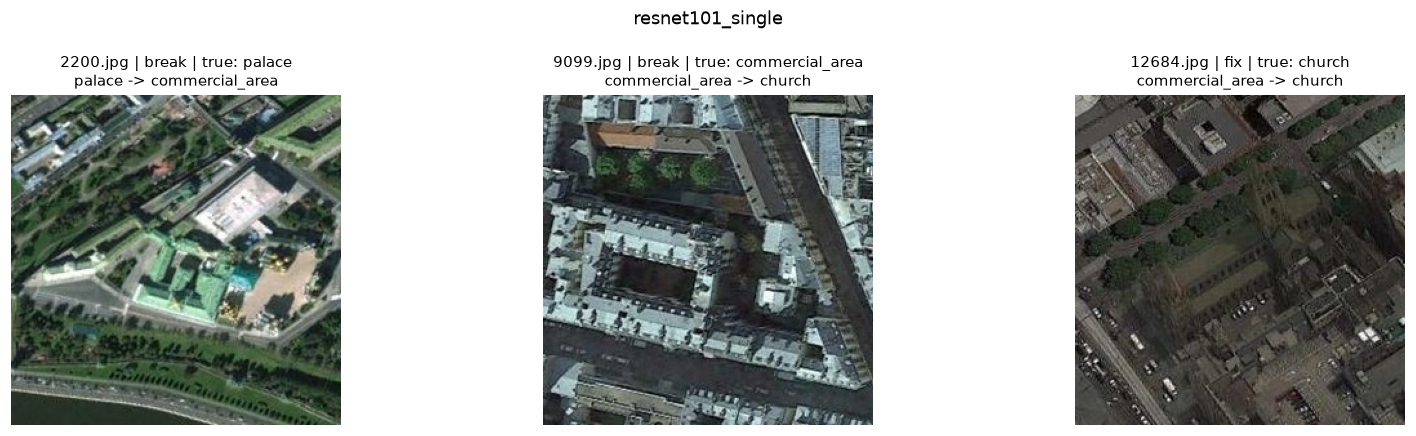

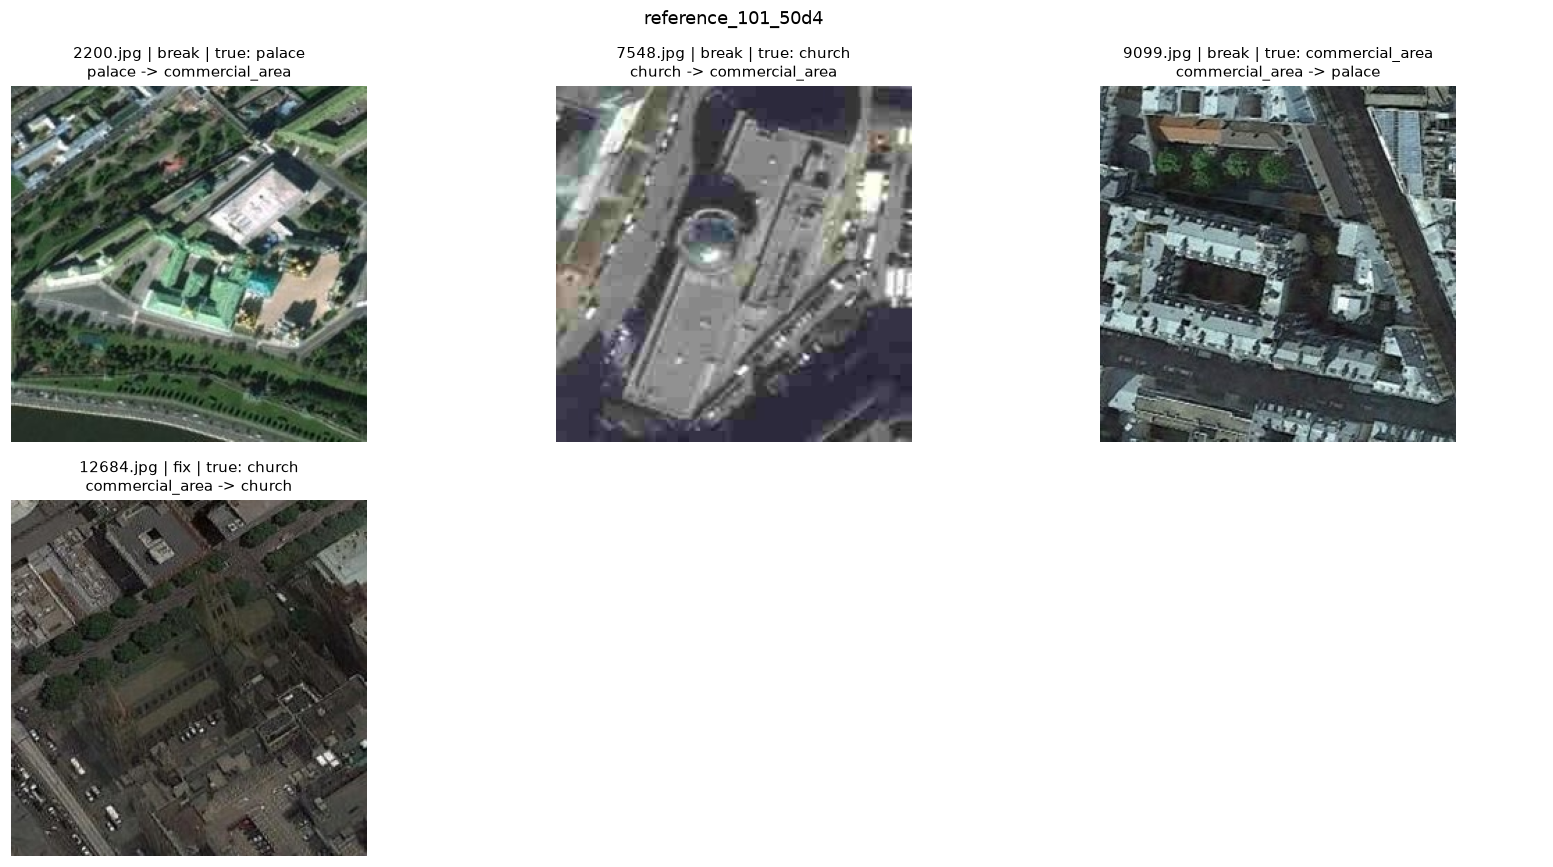

In [6]:
from PIL import Image
for base in ['resnet101_single','reference_101_50d4']:
    changes = pd.read_csv(pair_logs/f'{base}_changes.csv', dtype={'id':str})
    if changes.empty:
        print(base, 'no changed labels'); continue
    for start in range(0,len(changes),9):
        page = changes.iloc[start:start+9]
        fig,axes = plt.subplots((len(page)+2)//3,3,figsize=(15,4*((len(page)+2)//3)),squeeze=False)
        for ax,row in zip(axes.flat,page.itertuples()):
            directory=(PROJECT_ROOT/'data/raw/val').resolve()
            image_path=(directory/row.id).resolve()
            if not image_path.is_relative_to(directory): raise ValueError('ID escapes val')
            with Image.open(image_path) as image: ax.imshow(image.convert('RGB'))
            ax.set_title(f'{row.id} | {row.change} | true: {row.true_class}\n{row.reference_class} -> {row.predicted_class}',fontsize=10)
            ax.axis('off')
        for ax in list(axes.flat)[len(page):]: ax.axis('off')
        fig.suptitle(base); fig.tight_layout(); plt.show()


## После выбора pipeline

Сначала сравнить общий баланс fixes/breaks, особенно на church/palace/commercial_area. Не выбирать отдельные ошибки вручную и не подбирать порог на каждом снимке. Если нет прироста, оставить reference.

По подтверждённым пользователем правилам финальный train+val refit разрешён. Он вынесен в **09_final_refit.ipynb**, отключён по умолчанию и требует Kaggle GPU. После него бывшая val не служит held-out метрикой или источником выбора checkpoint. Подготовленные train+val presets — финальное обучение выбранного partial+stronger, не ещё один full-контроль.
